# Big Data Analytics (BDA) & Spatial Gap Analysis — Surabaya Timur

Agregasi multimodal per kecamatan, perhitungan Digital Gap Index, dan pemetaan sebaran UMKM.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT_DIR = Path.cwd().resolve()
if not (ROOT_DIR / 'data').exists() and (ROOT_DIR.parent.parent / 'data').exists():
    ROOT_DIR = ROOT_DIR.parent.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

CLEAN_DIR = ROOT_DIR / 'data' / 'clean'
GOLD_DIR = ROOT_DIR / 'data' / 'gold'
REPORTS_DIR = ROOT_DIR / 'peta-digital-umkm' / 'reports'
GDRIVE_OUT = Path('G:/My Drive/Iqbal-BDA')
OUT_DIR = GDRIVE_OUT if GDRIVE_OUT.parent.exists() else (REPORTS_DIR / 'iqbal-bda')
OUT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120

def save_and_show(filename: str) -> None:
    out_path = OUT_DIR / filename
    plt.tight_layout()
    plt.savefig(out_path, dpi=200, bbox_inches='tight')
    print(f'Saved: {out_path}')
    plt.show()

print(f'Project Root : {ROOT_DIR}')
print(f'Clean Data   : {CLEAN_DIR}')
print(f'Output Dir   : {OUT_DIR}')

Project Root : C:\big-data-analytic
Clean Data   : C:\big-data-analytic\data\clean
Output Dir   : G:\My Drive\Iqbal-BDA


## 1. Tabel Kesenjangan Digital per Kecamatan

In [2]:
gap_csv = REPORTS_DIR / 'bda' / 'kecamatan_digital_gap.csv'
df_gap = pd.read_csv(gap_csv)
display(df_gap)

,kecamatan,total_umkm,qris_rate,ojol_rate,pos_rate,edc_rate,avg_rating,avg_maturity_score,digital_gap_index,rekomendasi_intervensi
0,Gubeng,172,14.53,9.30,4.65,0.00,4.56,11.88,88.12,Prioritas Tinggi (Pendampingan Intensif QRIS &...
1,Gunung Anyar,50,16.00,22.00,2.00,0.00,4.55,14.75,85.25,Prioritas Tinggi (Pendampingan Intensif QRIS &...
2,Tenggilis Mejoyo,42,26.19,14.29,7.14,0.00,4.47,16.80,83.20,Prioritas Tinggi (Pendampingan Intensif QRIS &...
3,Rungkut,59,28.81,18.64,0.00,3.39,4.56,17.65,82.35,Prioritas Tinggi (Pendampingan Intensif QRIS &...
4,Sukolilo,35,31.43,20.00,5.71,2.86,4.60,19.91,80.09,Prioritas Tinggi (Pendampingan Intensif QRIS &...
5,Mulyorejo,27,44.44,22.22,7.41,0.00,4.56,23.97,76.03,Prioritas Menengah (Akselerasi POS Kasir Digital)


Saved: G:\My Drive\Iqbal-BDA\01_penetrasi_digital_kecamatan.png


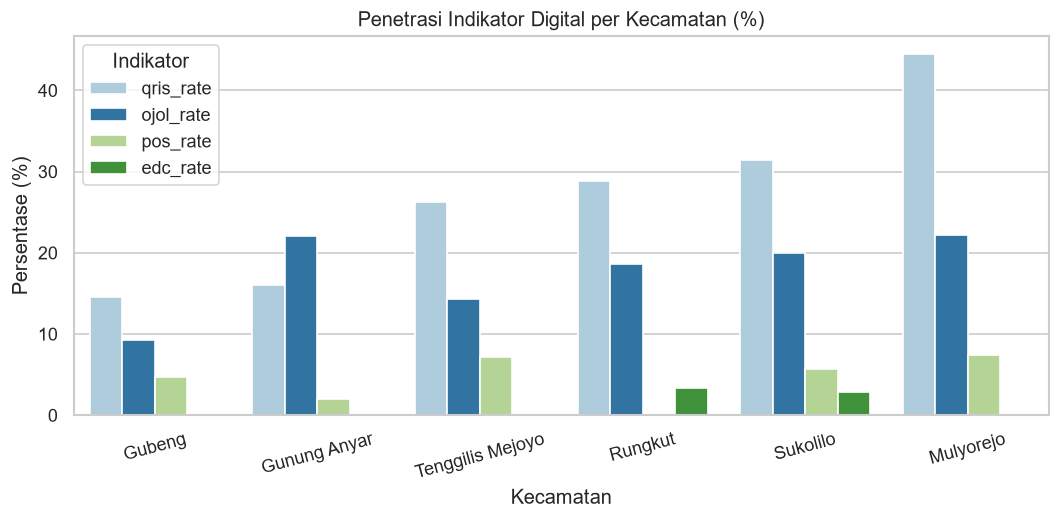

In [3]:
melted = df_gap.melt(
    id_vars='kecamatan',
    value_vars=['qris_rate', 'ojol_rate', 'pos_rate', 'edc_rate'],
    var_name='Indikator',
    value_name='Persentase (%)',
)
plt.figure(figsize=(9.0, 4.5))
sns.barplot(data=melted, x='kecamatan', y='Persentase (%)', hue='Indikator', palette='Paired')
plt.title('Penetrasi Indikator Digital per Kecamatan (%)')
plt.xlabel('Kecamatan')
plt.xticks(rotation=15)
save_and_show('01_penetrasi_digital_kecamatan.png')

## 2. Digital Gap Index & Sebaran Geospasial

Saved: G:\My Drive\Iqbal-BDA\02_indeks_kematangan_kecamatan.png


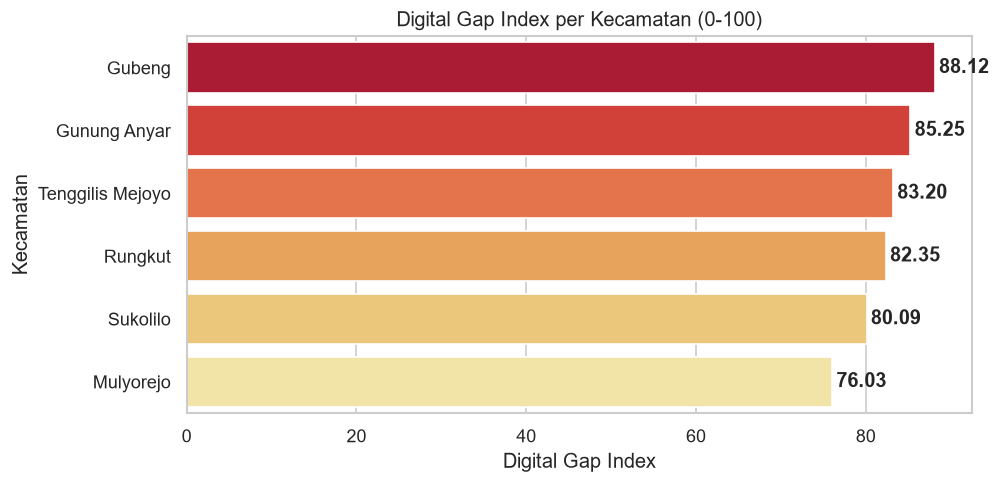

In [4]:
plt.figure(figsize=(8.5, 4.2))
sns.barplot(data=df_gap, x='digital_gap_index', y='kecamatan', hue='kecamatan', palette='YlOrRd_r', legend=False)
plt.title('Digital Gap Index per Kecamatan (0-100)')
plt.xlabel('Digital Gap Index')
plt.ylabel('Kecamatan')
for idx, val in enumerate(df_gap['digital_gap_index']):
    plt.text(val + 0.5, idx, f'{val:.2f}', va='center', fontweight='bold')
save_and_show('02_indeks_kematangan_kecamatan.png')

Saved: G:\My Drive\Iqbal-BDA\03_peta_sebaran_kematangan_umkm.png


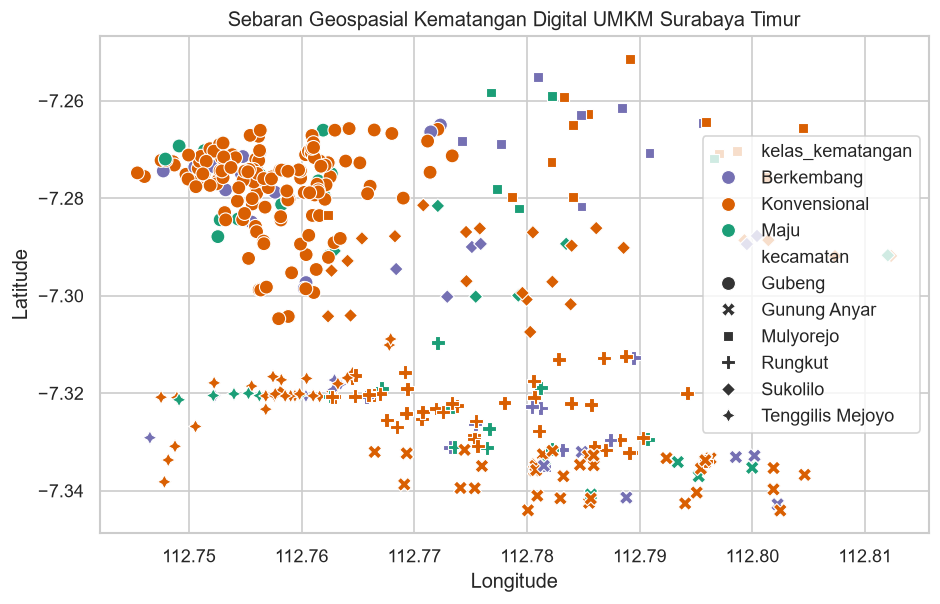

In [5]:
df_feat = pd.read_parquet(GOLD_DIR / 'feature_store.parquet')
plt.figure(figsize=(8.0, 5.2))
sns.scatterplot(
    data=df_feat,
    x='lon',
    y='lat',
    hue='kelas_kematangan',
    style='kecamatan',
    palette={'Konvensional': '#d95f02', 'Berkembang': '#7570b3', 'Maju': '#1b9e77'},
    s=70,
)
plt.title('Sebaran Geospasial Kematangan Digital UMKM Surabaya Timur')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
save_and_show('03_peta_sebaran_kematangan_umkm.png')

## 3. Sentra Wisata Kuliner (SWK) Terdaftar

In [6]:
df_umkm = pd.read_parquet(CLEAN_DIR / 'umkm.parquet')
swk_df = df_umkm[df_umkm['tipe_lokasi'] == 'SWK']
print(f'Total SWK terdaftar di Google Places API: {len(swk_df)}')
display(swk_df[['umkm_id', 'nama_umkm', 'kecamatan', 'rating', 'alamat']])

Total SWK terdaftar di Google Places API: 7


,umkm_id,nama_umkm,kecamatan,rating,alamat
0,UMKM_SBY_0001,Sentra Wisata Kuliner Bratang Binangun,Gubeng,4.5,"Jl. Raya Manyar No.80A, Baratajaya, Kec. Guben..."
50,UMKM_SBY_0051,Sentra Wisata Kuliner Dharmahusada,Mulyorejo,4.4,"Pojok Timur, Jl. Dharmahusada, Mulyorejo, Kec...."
55,UMKM_SBY_0056,Sentra Wisata Kuliner Convention Hall,Sukolilo,4.3,"Arief Rahman Hakim No.131, Keputih, Kec. Sukol..."
70,UMKM_SBY_0071,Sentra Wisata Kuliner (SWK) Rungkut Kidul,Rungkut,4.9,"Jl. Rungkut Asri No.3, Rungkut Kidul, Kec. Run..."
91,UMKM_SBY_0092,Sentra Wisata Kuliner Semolowaru,Sukolilo,4.4,"Semolowaru, Sukolilo, Surabaya, East Java 6011..."
93,UMKM_SBY_0094,Wisata Kuliner Deles,Sukolilo,4.4,"Arief Rahman Hakim No.14, Keputih, Kec. Sukoli..."
375,UMKM_SBY_0376,SWK Klampis Ngasem,Sukolilo,4.4,"Jl. Dr. Ir. H. Soekarno, Klampis Ngasem, Kec. ..."
